In [47]:
import pandas as pd 
train=pd.read_csv("train.csv")
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# 1. Introduction

L'objectif de ce projet est de prédire la survie des passagers du Titanic à l'aide de techniques de Machine Learning.

Le projet comprend le nettoyage des données, l'analyse exploratoire, la préparation des variables, l'entraînement de modèles et l'évaluation de leurs performances.

In [2]:
print("Dimensions du dataset : ", train.shape)
print("\n Informations du dataset : " )
train.info()

Dimensions du dataset :  (891, 12)

 Informations du dataset : 
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


# 3. Nettoyage des données

In [4]:
train_clean=train.copy()

In [5]:
mediane_age = train_clean["Age"].median()
train_clean["Age"]=train_clean["Age"].fillna(mediane_age)
print("Médiane des ages : " ,mediane_age )
print("Valeurs manquantes restants :" , train_clean["Age"].isnull().sum())


Médiane des ages :  28.0
Valeurs manquantes restants : 0


In [6]:
port_frequent=train_clean["Embarked"].mode()[0]
train_clean["Embarked"]=train_clean["Embarked"].fillna(port_frequent)
print("Port le plus fréquent :" , port_frequent)
print("Valeurs manquantes restants :" , train_clean["Embarked"].isnull().sum())



Port le plus fréquent : S
Valeurs manquantes restants : 0


In [7]:
print("Dimensions :", train_clean.shape)
print("Colonnes :", train_clean.columns.tolist())

Dimensions : (891, 12)
Colonnes : ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [8]:
train_clean.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [9]:
train_clean["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [10]:
pourcentages=train_clean["Survived"].value_counts(normalize=True)*100
print(pourcentages)

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


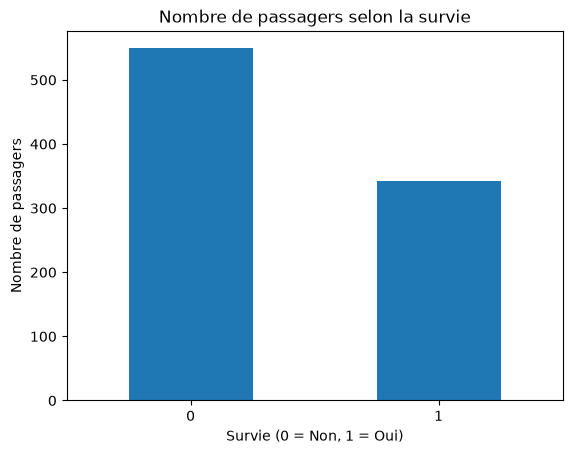

In [11]:
import matplotlib.pyplot as plt

comptages = train_clean["Survived"].value_counts().sort_index()

comptages.plot(kind="bar")

plt.title("Nombre de passagers selon la survie")
plt.xlabel("Survie (0 = Non, 1 = Oui)")
plt.ylabel("Nombre de passagers")
plt.xticks(rotation=0)

plt.show()

In [12]:
train_clean.groupby("Sex")["Survived"].mean()*100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

# 4. Analyse exploratoire des données (EDA)

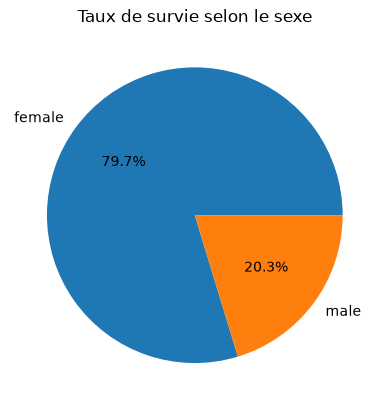

In [13]:
taux_survie=train_clean.groupby("Sex")["Survived"].mean()*100
taux_survie.plot(kind="pie" , autopct="%1.1f%%")

plt.title("Taux de survie selon le sexe")

plt.show()


In [14]:
train_clean["Age"].describe()

count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64

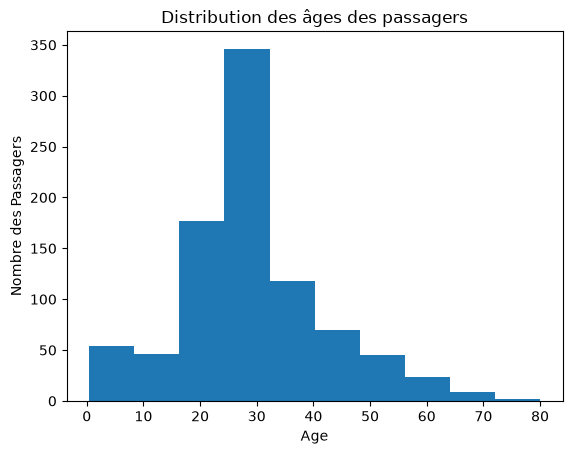

In [15]:
train_clean["Age"].plot(kind="hist" , bins=10)

plt.title("Distribution des âges des passagers")
plt.xlabel("Age")
plt.ylabel("Nombre des Passagers")
plt.show()

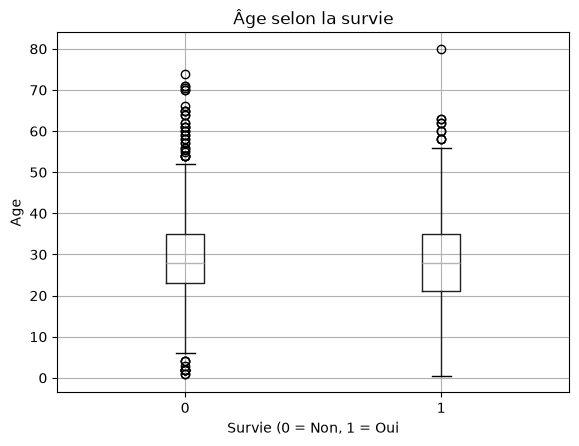

In [16]:
train_clean.boxplot( column="Age" , by="Survived")

plt.title("Âge selon la survie")
plt.suptitle("")
plt.xlabel("Survie (0 = Non, 1 = Oui")
plt.ylabel("Age")

plt.show()

In [17]:
taux_survie_classe=train_clean.groupby("Pclass")["Survived"].mean()*100
print(taux_survie_classe)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


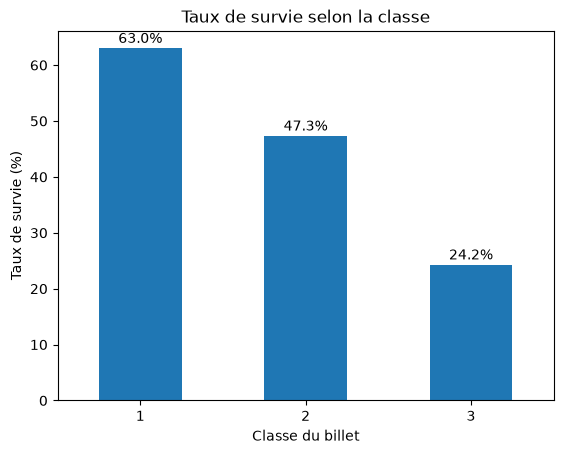

In [18]:
taux_survie_classe.plot(kind="bar")

plt.title("Taux de survie selon la classe")
plt.xlabel("Classe du billet")
plt.ylabel("Taux de survie (%)")
plt.xticks(rotation=0)

for i, taux in enumerate(taux_survie_classe):
    plt.text(i, taux + 1, f"{taux:.1f}%", ha="center")

plt.show()

In [19]:
taux_survie_port=train_clean.groupby("Embarked")["Survived"].mean()*100
print(taux_survie_port)


Embarked
C    55.357143
Q    38.961039
S    33.900929
Name: Survived, dtype: float64


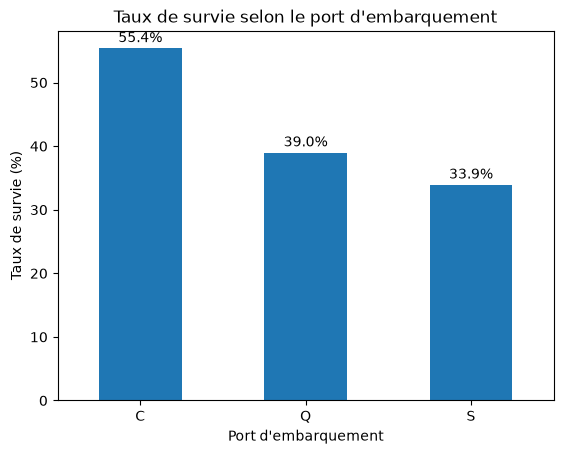

In [20]:
taux_survie_port.plot(kind="bar")

plt.title("Taux de survie selon le port d'embarquement")
plt.xlabel("Port d'embarquement")
plt.ylabel("Taux de survie (%)")
plt.xticks(rotation=0)

for i, taux in enumerate(taux_survie_port):
    plt.text(i, taux + 1, f"{taux:.1f}%", ha="center")

plt.show()

In [21]:
taux_survie_sexe_classe=train_clean.groupby(["Sex","Pclass"])["Survived"].mean()*100
print(taux_survie_sexe_classe)

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64


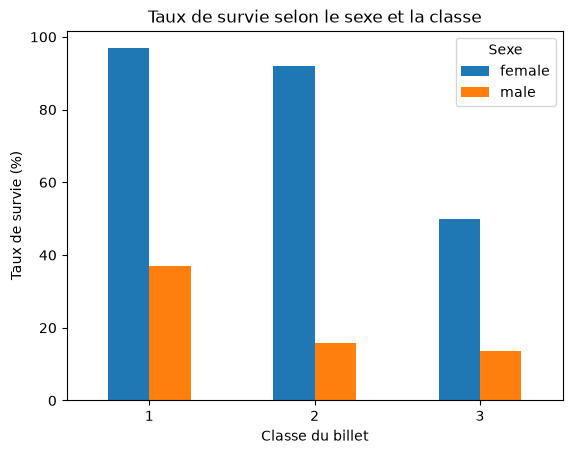

In [22]:
table_survie=train_clean.pivot_table(    index="Pclass",
    columns="Sex",
    values="Survived",
    aggfunc="mean"
) * 100
table_survie.plot(kind="bar")

plt.title("Taux de survie selon le sexe et la classe")
plt.xlabel("Classe du billet")
plt.ylabel("Taux de survie (%)")
plt.xticks(rotation=0)
plt.legend(title="Sexe")
plt.show()

In [23]:
taux_survie_sibsp = train_clean.groupby("SibSp")["Survived"].mean() * 100

print(taux_survie_sibsp)

SibSp
0    34.539474
1    53.588517
2    46.428571
3    25.000000
4    16.666667
5     0.000000
8     0.000000
Name: Survived, dtype: float64


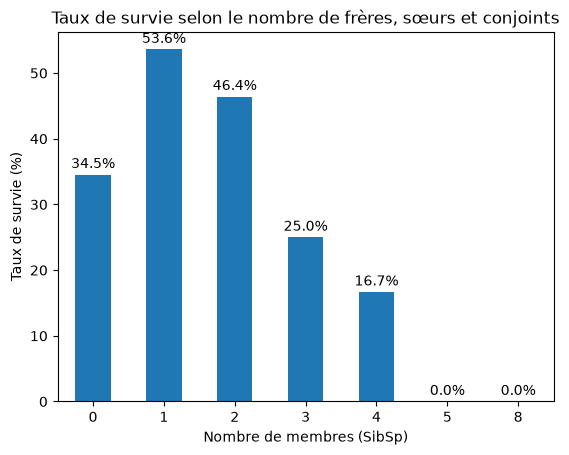

In [24]:
taux_survie_sibsp.plot(kind="bar")

plt.title("Taux de survie selon le nombre de frères, sœurs et conjoints")
plt.xlabel("Nombre de membres (SibSp)")
plt.ylabel("Taux de survie (%)")
plt.xticks(rotation=0)

for i, taux in enumerate(taux_survie_sibsp):
    plt.text(i, taux + 1, f"{taux:.1f}%", ha="center")

plt.show()

In [25]:
taux_survie_parch = train_clean.groupby("Parch")["Survived"].mean() * 100

print(taux_survie_parch)

Parch
0    34.365782
1    55.084746
2    50.000000
3    60.000000
4     0.000000
5    20.000000
6     0.000000
Name: Survived, dtype: float64


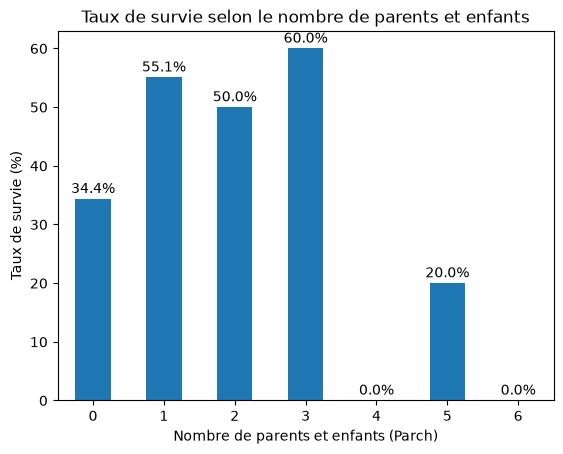

In [26]:
taux_survie_parch.plot(kind="bar")

plt.title("Taux de survie selon le nombre de parents et enfants")
plt.xlabel("Nombre de parents et enfants (Parch)")
plt.ylabel("Taux de survie (%)")
plt.xticks(rotation=0)

for i, taux in enumerate(taux_survie_parch):
    plt.text(i, taux + 1, f"{taux:.1f}%", ha="center")

plt.show()

In [27]:
X = train_clean[
    ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
]

y = train_clean["Survived"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (891, 7)
Dimensions de y : (891,)


# 5. Préparation des données

In [28]:
X = pd.get_dummies(X, columns=["Sex", "Embarked"], drop_first=True)
print(X.head())
print(X.dtypes)

   Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
0       3  22.0      1      0   7.2500      True       False        True
1       1  38.0      1      0  71.2833     False       False       False
2       3  26.0      0      0   7.9250     False       False        True
3       1  35.0      1      0  53.1000     False       False        True
4       3  35.0      0      0   8.0500      True       False        True
Pclass          int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Sex_male         bool
Embarked_Q       bool
Embarked_S       bool
dtype: object


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (712, 8)
X_test : (179, 8)
y_train : (712,)
y_test : (179,)


# 6. Entraînement des modèles

In [30]:
from sklearn.linear_model import LogisticRegression
modele = LogisticRegression(max_iter=1000)

modele.fit(X_train, y_train)

print("Entraînement terminé !")

Entraînement terminé !


In [31]:
y_pred = modele.predict(X_test)

print("Premières prédictions :", y_pred[:10])
print("Résultats réels :", y_test.iloc[:10].values)

Premières prédictions : [0 0 0 0 1 0 1 0 0 0]
Résultats réels : [0 0 1 0 1 1 1 0 0 0]


In [32]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy du modèle : {accuracy * 100:.2f}%")

Accuracy du modèle : 80.45%


Matrice de confusion :
[[98 12]
 [23 46]]


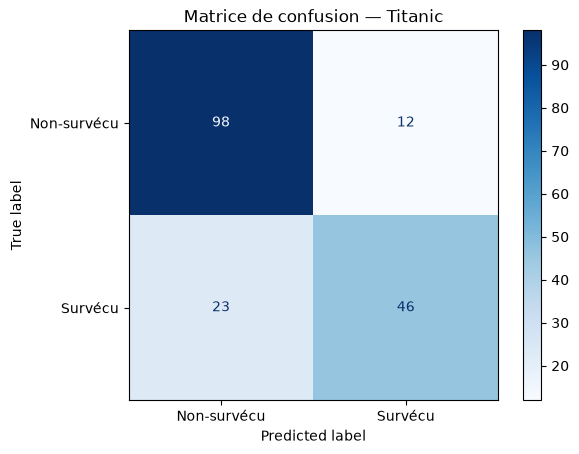

In [33]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Matrice de confusion :")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-survécu", "Survécu"]
)

disp.plot(cmap="Blues")
plt.title("Matrice de confusion — Titanic")
plt.show()


In [34]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-survécu", "Survécu"]
))


              precision    recall  f1-score   support

 Non-survécu       0.81      0.89      0.85       110
     Survécu       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [35]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

modele_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

modele_rf.fit(X_train, y_train)

y_pred_rf = modele_rf.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f"Accuracy Logistic Regression : {accuracy * 100:.2f}%")
print(f"Accuracy Random Forest      : {accuracy_rf * 100:.2f}%")


Accuracy Logistic Regression : 80.45%
Accuracy Random Forest      : 81.56%


In [36]:

from sklearn.metrics import classification_report

print("Rapport Random Forest :")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Non-survécu", "Survécu"]
))


Rapport Random Forest :
              precision    recall  f1-score   support

 Non-survécu       0.83      0.87      0.85       110
     Survécu       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



# 7. Évaluation et comparaison des modèles

In [37]:

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score

comparaison = pd.DataFrame({
    "Modèle": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Recall (survivants)": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score (survivants)": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf)
    ]
})

comparaison = comparaison.sort_values(
    by="Accuracy", ascending=False
)

comparaison.round(3)


,Modèle,Accuracy,Recall (survivants),F1-score (survivants)
1,Random Forest,0.816,0.725,0.752
0,Logistic Regression,0.804,0.667,0.724


In [38]:

from sklearn.metrics import accuracy_score

y_train_pred_lr = modele.predict(X_train)
y_train_pred_rf = modele_rf.predict(X_train)

print("=== Logistic Regression ===")
print(f"Train Accuracy : {accuracy_score(y_train, y_train_pred_lr) * 100:.2f}%")
print(f"Test Accuracy  : {accuracy_score(y_test, y_pred) * 100:.2f}%")

print("\n=== Random Forest ===")
print(f"Train Accuracy : {accuracy_score(y_train, y_train_pred_rf) * 100:.2f}%")
print(f"Test Accuracy  : {accuracy_score(y_test, y_pred_rf) * 100:.2f}%")


=== Logistic Regression ===
Train Accuracy : 80.76%
Test Accuracy  : 80.45%

=== Random Forest ===
Train Accuracy : 98.17%
Test Accuracy  : 81.56%


In [41]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

modele_rf_ajuste = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=5,
    random_state=42
)

modele_rf_ajuste.fit(X_train, y_train)

y_train_pred_rf_ajuste = modele_rf_ajuste.predict(X_train)
y_test_pred_rf_ajuste = modele_rf_ajuste.predict(X_test)

print(" Random Forest ajusté : ")
print(f"Train Accuracy : {accuracy_score(y_train, y_train_pred_rf_ajuste) * 100:.2f}%")
print(f"Test Accuracy  : {accuracy_score(y_test, y_test_pred_rf_ajuste) * 100:.2f}%")


 Random Forest ajusté : 
Train Accuracy : 84.69%
Test Accuracy  : 80.45%


In [42]:

from sklearn.metrics import accuracy_score, recall_score, f1_score

modeles = {
    "Logistic Regression": (y_pred, y_train_pred_lr),
    "Random Forest initial": (y_pred_rf, y_train_pred_rf),
    "Random Forest ajusté": (
        y_test_pred_rf_ajuste,
        y_train_pred_rf_ajuste
    )
}

for nom, (pred_test, pred_train) in modeles.items():
    print(f"\n {nom} ")
    print(f"Accuracy : {accuracy_score(y_test, pred_test) * 100:.2f}%")
    print(f"Recall survivants : {recall_score(y_test, pred_test) * 100:.2f}%")
    print(f"F1-score survivants : {f1_score(y_test, pred_test) * 100:.2f}%")



 Logistic Regression 
Accuracy : 80.45%
Recall survivants : 66.67%
F1-score survivants : 72.44%

 Random Forest initial 
Accuracy : 81.56%
Recall survivants : 72.46%
F1-score survivants : 75.19%

 Random Forest ajusté 
Accuracy : 80.45%
Recall survivants : 59.42%
F1-score survivants : 70.09%


# 8. Validation croisée


In [43]:

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

modele_rf_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scores = cross_val_score(
    modele_rf_cv,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Scores des 5 folds :", scores.round(3))
print(f"Accuracy moyenne : {scores.mean() * 100:.2f}%")
print(f"Écart-type : {scores.std() * 100:.2f}%")


Scores des 5 folds : [0.799 0.815 0.848 0.787 0.82 ]
Accuracy moyenne : 81.37%
Écart-type : 2.10%


# 9. Conclusion générale

Dans ce projet, j'ai travaillé sur les données des passagers du Titanic pour essayer de prédire s'ils ont survécu ou non. J'ai commencé par nettoyer les données, puis j'ai réalisé plusieurs analyses et graphiques pour mieux comprendre les facteurs qui peuvent influencer la survie.

Ensuite, j'ai préparé les données et testé deux algorithmes de Machine Learning : Logistic Regression et Random Forest. J'ai comparé leurs résultats en utilisant plusieurs mesures, comme l'Accuracy, le Recall et le F1-score.

Le modèle Random Forest a obtenu le meilleur résultat sur les données de test, avec une Accuracy de **81,56 %**. La validation croisée a également donné une Accuracy moyenne de **81,37 %**. Ces résultats sont encourageants, mais le modèle présente encore quelques limites, notamment un risque de surapprentissage.

Ce projet m'a permis de mieux comprendre les différentes étapes d'un projet de Machine Learning, depuis la préparation des données jusqu'à l'évaluation des modèles. Il m'a aussi permis de pratiquer Python et plusieurs bibliothèques utilisées en Data Science. Pour améliorer ce travail, je pourrais essayer d'autres paramètres et méthodes afin d'obtenir de meilleurs résultats.